# Introduction to Classification

In [1]:
import pandas as pd
import numpy as np

## Classifying Tropical Storms

The "storms" data set contains data on tropical storms since 1975. Suppose we want to use this data to train a classification model that predicts whether or not a storm is a hurricane based on its wind speed and pressure.


In [2]:
df_storms = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/main/data/storms.csv")
df_storms["hurricane"] = (df_storms["status"] == "hurricane")
df_storms


,name,year,month,day,hour,lat,long,status,category,wind,pressure,tropicalstorm_force_diameter,hurricane_force_diameter,hurricane
0,Amy,1975,6,27,0,27.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
1,Amy,1975,6,27,6,28.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
2,Amy,1975,6,27,12,29.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
3,Amy,1975,6,27,18,30.5,-79.0,tropical depression,NaN,25,1013,NaN,NaN,False
4,Amy,1975,6,28,0,31.5,-78.8,tropical depression,NaN,25,1012,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19061,Wanda,2021,11,7,0,37.4,-37.4,tropical storm,NaN,35,1003,60.0,0.0,False
19062,Wanda,2021,11,7,6,38.1,-36.4,tropical storm,NaN,35,1004,60.0,0.0,False
19063,Wanda,2021,11,7,12,39.2,-34.9,other low,NaN,35,1006,90.0,0.0,False
19064,Wanda,2021,11,7,18,40.9,-32.8,other low,NaN,40,1006,90.0,0.0,False


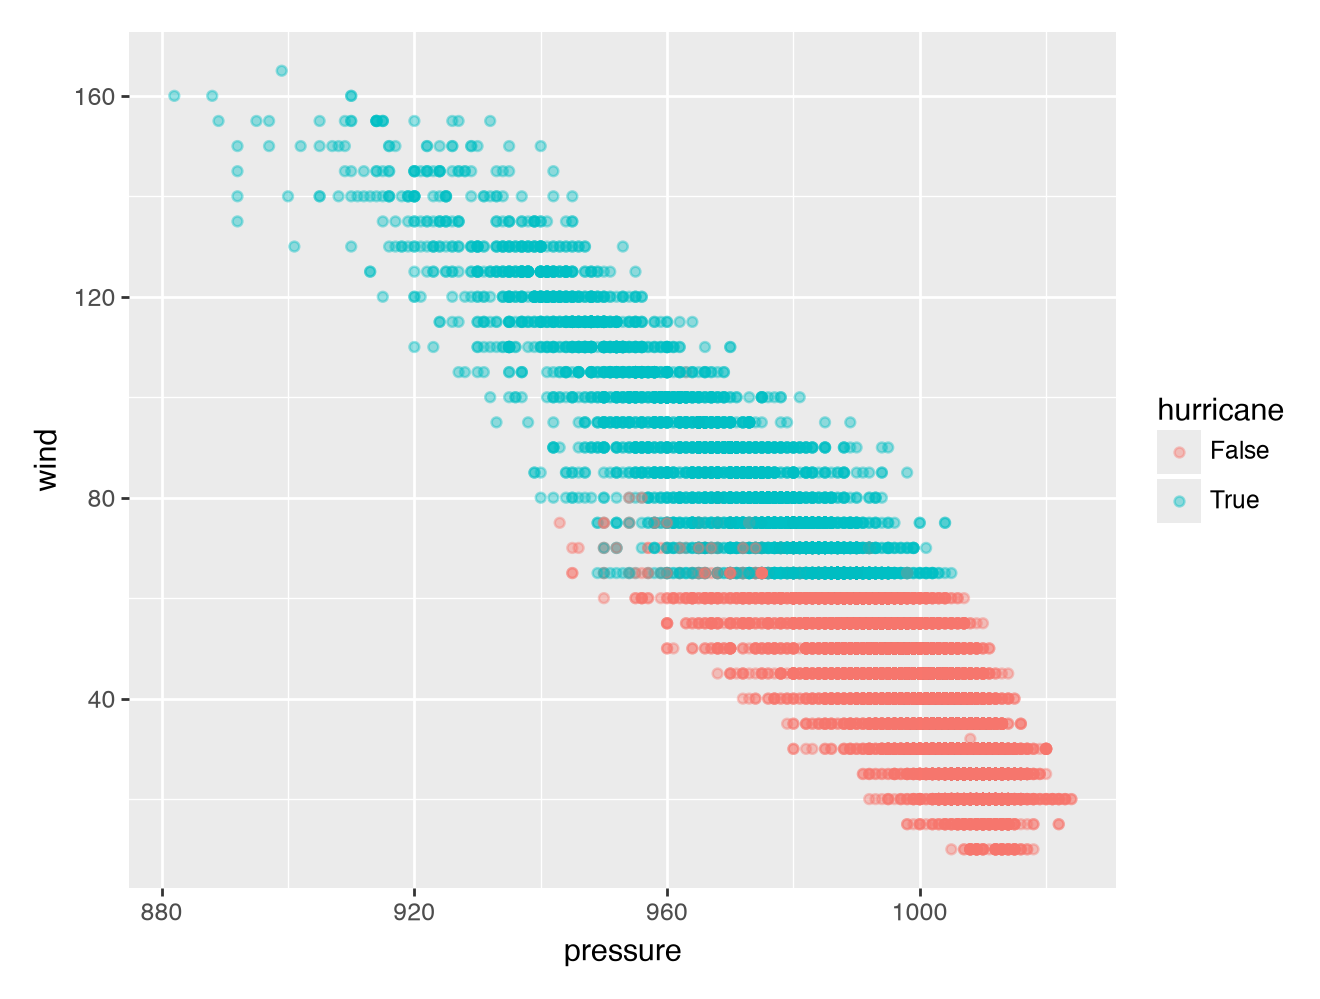

In [3]:
from plotnine import *

(
    ggplot(
        df_storms,
        aes(x="pressure", y="wind", color="hurricane")
    )
    + geom_point(alpha=0.4)
)

1. Inspect the scatterplot above. Suggest a simple classification rule that you suspect will have both high precision and high recall for the hurriance class based on the training data. **Without doing any coding, specify your rule and explain your reasoning.** This is NOT asking you to do nearest neighbors. Rather suggest a simple classification rule based on what you see in the plot.

Predict hurricane if wind ≥ 65. In the plot, hurricanes sit almost entirely above wind ≈ 65 and non-hurricanes almost entirely below it. Pressure overlaps too much between the classes to help.

**DISCUSS WITH YOUR PARTNER.**

2. For each of the following **compute the value and write a clearly worded sentence interpreting the value as a percentage in context.** Again, this is NOT asking you to fit a nearest neighbors model. You can write code, but you should only need to write basic code to make your predictions and get relevant counts from the training data. You can compute things like fractions by hand.

  a. training accuracy  
  b. training precision for the hurricane class  
  c. training recall for the hurricane class  
  d. training F1 score for the hurricane class  
  e. training precision for the non-hurricane class    
  f. training precision for the non-hurricane class  
  g. training F1 score for the non-hurricane class  

In [4]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

actual = df_storms["hurricane"]                 # True = hurricane (the positive class)
predicted = df_storms["wind"] >= 64             # the rule from question 1

cm = confusion_matrix(actual, predicted, labels=[True, False])   # rows: actual hurricane / not; columns: predicted hurricane / not
TP, FN, FP, TN = cm.ravel()
n = len(actual)
print(pd.DataFrame(cm, index=["actual hurricane", "actual non-hurricane"], columns=["predicted hurricane", "predicted non-hurricane"]))
print(f"\nTP = {TP}   FN = {FN}   FP = {FP}   TN = {TN}   n = {n}")

                      predicted hurricane  predicted non-hurricane
actual hurricane                     4684                        0
actual non-hurricane                  128                    14254

TP = 4684   FN = 0   FP = 128   TN = 14254   n = 19066


a. Accuracy = (4684 + 14254)/19066 = 99.3%. The rule correctly classifies 99.3% of storm observations.

b. Precision (hurricane) = 4684/4812 = 97.3%. Of the observations the rule calls hurricanes, 97.3% are actually hurricanes.

c. Recall (hurricane) = 4684/4684 = 100%. The rule catches 100% of actual hurricanes.

d. F1 (hurricane) = 2(0.973)(1)/(0.973 + 1) = 98.7%.

e. Precision (non-hurricane) = 14254/14254 = 100%. Every observation the rule calls a non-hurricane is actually a non-hurricane.

f. (same question as e)

g. F1 (non-hurricane) = 2(1)(0.991)/(1 + 0.991) = 99.6%.

**DISCUSS WITH YOUR PARTNER.**

3. The "status" variable contains further breakdown of the non-hurricane class. Suppose we fit a **10-nearest neighbors** classification model for predicting status from wind speed and pressure. Without doing any coding, what status would the model predict for a storm with a pressure of 975 and wind speed of 39? **Explain your reasoning without doing any coding**. Hint: look at the scatterplot below, but be careful since some points are superimposed.

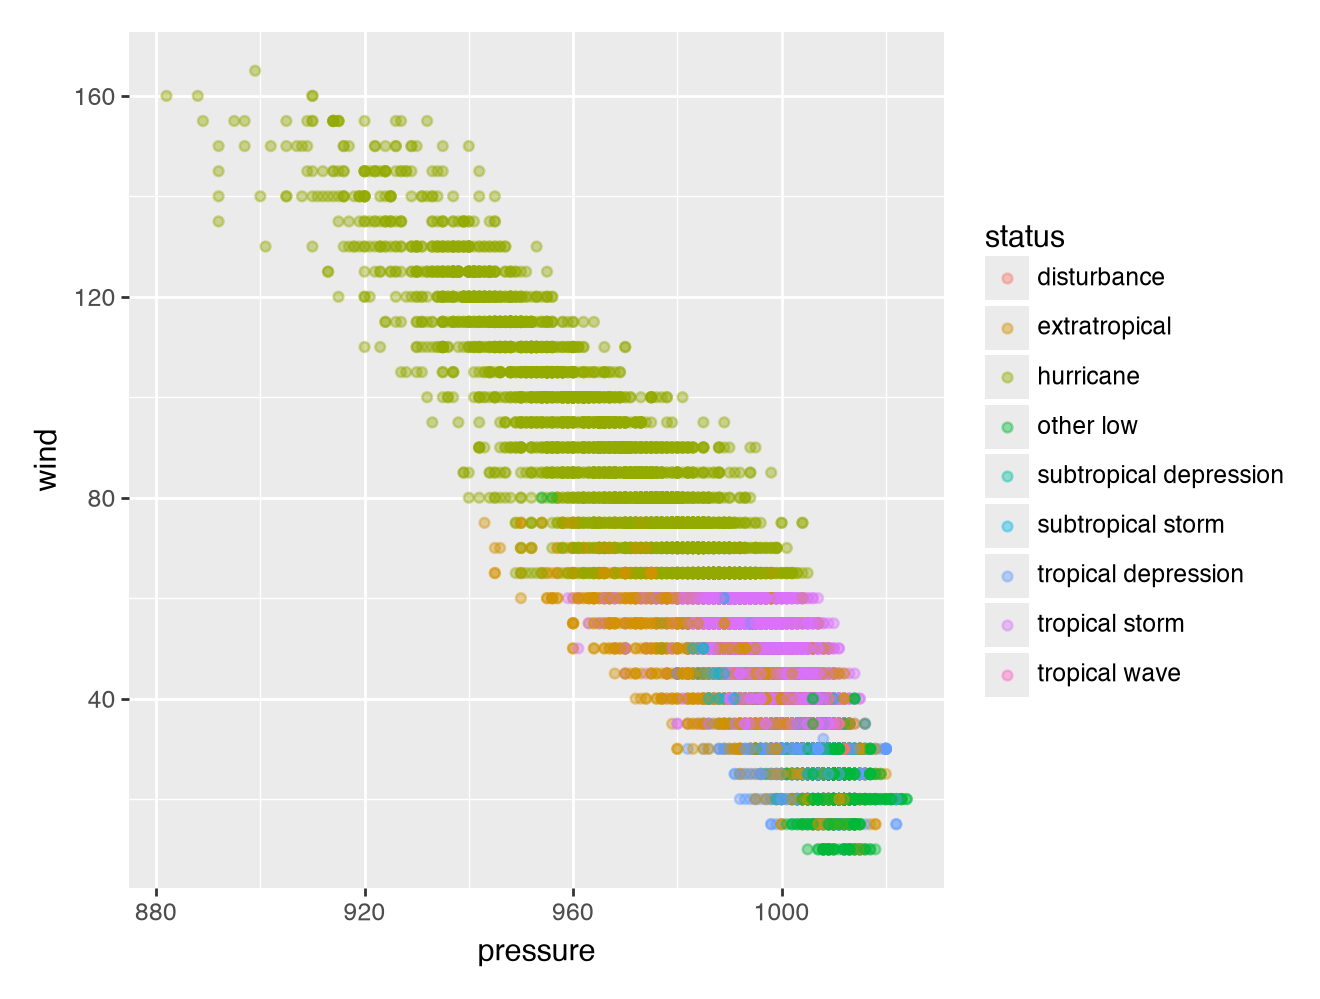

In [5]:
(
    ggplot(
        df_storms,
        aes(x="pressure", y="wind", color="status")
    )
    + geom_point(alpha=0.4)
)

The model would predict extratropical. At pressure 975, the low wind region of the plot is dominated by extratropical storms. Tropical storms with wind near 39 mostly have higher pressure, around 1000 and up. So most or all of the 10 nearest points are extratropical.

**DISCUSS WITH YOUR PARTNER.**

4. Suppose we fit a **10-nearest neighbors** classification model for predicting status from wind speed and pressure. Without doing any coding, which classes do you think would have the lowest recall based on the training data? **Explain your reasoning without doing any coding.** Hint: look at the scatterplot above, but be careful since some points are superimposed.

The small classes have the lowest recall (tropical wave, disturbance, subtropical storm, subtropical depression and other low). These classes have few points, and in the plot they sit on top of the big classes at similar wind and pressure values. So among any storm’s 10 nearest neighbors, the common classes almost always win the vote, and the small classes rarely get predicted. Few predictions means low recall.

**DISCUSS WITH YOUR PARTNER.**

## Practice Activity Titanic Data

We'll use $k$-nearest neighbors to predict who survives based on age, sex, and class.

In [6]:
df_titanic = pd.read_csv("https://dlsun.github.io/pods/data/titanic.csv ")

# drop the NaN for age since we're using it as a predictor
df_titanic = df_titanic.dropna(subset = ["age"])

df_titanic

,name,gender,age,class,embarked,country,ticketno,fare,survived
0,"Abbing, Mr. Anthony",male,42.0,3rd,S,United States,5547.0,7.11,0
1,"Abbott, Mr. Eugene Joseph",male,13.0,3rd,S,United States,2673.0,20.05,0
2,"Abbott, Mr. Rossmore Edward",male,16.0,3rd,S,United States,2673.0,20.05,0
3,"Abbott, Mrs. Rhoda Mary 'Rosa'",female,39.0,3rd,S,England,2673.0,20.05,1
4,"Abelseth, Miss. Karen Marie",female,16.0,3rd,S,Norway,348125.0,7.13,1
...,...,...,...,...,...,...,...,...,...
2202,"Wynn, Mr. Walter",male,41.0,deck crew,B,England,NaN,NaN,1
2203,"Yearsley, Mr. Harry",male,40.0,victualling crew,S,England,NaN,NaN,1
2204,"Young, Mr. Francis James",male,32.0,engineering crew,S,England,NaN,NaN,0
2205,"Zanetti, Sig. Minio",male,20.0,restaurant staff,S,England,NaN,NaN,0


1\. Train a 10-nearest neighbors model to predict whether or not a passenger on the Titanic survived, using their age, sex, and class as features.

In [7]:
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier

In [8]:
features = ["age", "gender", "class"]
X_train = df_titanic[features]
y_train = df_titanic["survived"]

ct = make_column_transformer(
    (StandardScaler(), ["age"]),
    (OneHotEncoder(handle_unknown="ignore"), ["gender", "class"]),
)

pipeline = make_pipeline(ct, KNeighborsClassifier(n_neighbors=10))
pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('kneighborsclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['age','gender','class']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('standardscaler', ...), ('onehotencoder', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remainin

2\. Use your model to predict whether a 20-year old female in first-class would survive. What about a 20-year old female in third-class? What are the predicted probabilities for each?

In [9]:
new_passengers = pd.DataFrame({
    "age": [20, 20],
    "gender": ["female", "female"],
    "class": ["1st", "3rd"]
})

print(pipeline.predict(new_passengers))
print(pipeline.classes_)
print(pipeline.predict_proba(new_passengers))

[1 0]
[0 1]
[[0.  1. ]
 [0.8 0.2]]


20-year-old female, first class: the model predicts she survives. P(survived) = 1.0

20-year-old female, third class: the model predicts she does not survive. P(survived) = 0.2

3\. Calculate and interpret the training precision, recall, and F1 score for predicting survivors.

In [10]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

y_train_pred = pipeline.predict(X_train)

print(confusion_matrix(y_train, y_train_pred))
print("precision:", precision_score(y_train, y_train_pred))
print("recall:", recall_score(y_train, y_train_pred))
print("F1:", f1_score(y_train, y_train_pred))

[[1427   67]
 [ 332  379]]
precision: 0.8497757847533632
recall: 0.5330520393811533
F1: 0.6551426101987899


Precision = 85.0% (379/446). Of the passengers the model predicts survived, 85.0% actually survived.

Recall = 53.3% (379/711). The model correctly identifies 53.3% of the passengers who actually survived.

F1 = 65.5%. This is the harmonic mean of precision and recall. Low recall pulls it down meaning the model misses almost half of the survivors.

4\. Calculate and interpret the training precision, recall, and F1 score for predicting non-survivors.

In [11]:
print("precision:", precision_score(y_train, y_train_pred, pos_label=0))
print("recall:", recall_score(y_train, y_train_pred, pos_label=0))
print("F1:", f1_score(y_train, y_train_pred, pos_label=0))

precision: 0.8112563956793633
recall: 0.9551539491298527
F1: 0.8773439901629265


Precision = 81.1% (1427/1759). Of the passengers the model predicts did not survive, 81.1% actually did not survive.
Recall = 95.5% (1427/1494). The model correctly identifies 95.5% of the passengers who did not survive.
F1 = 87.7%. It’s higher than the survivor F1 because both precision and recall are high for this class.

5\. Since there are only two classes (survived or not) the model predicts survival if the predicted probability of survival is $0.5$ or higher. Change the threshold from 0.5 to 0.8 and compute the precision and recall for survivors and the non-survivors. How do the values compare to those with the threshold of 0.5?

In [12]:
prob = pipeline.predict_proba(X_train)[:, 1]   # P(survived)
y_pred_08 = (prob >= 0.8).astype(int)

print(confusion_matrix(y_train, y_pred_08))
print("survivors     precision:", precision_score(y_train, y_pred_08),
      " recall:", recall_score(y_train, y_pred_08))
print("non-survivors precision:", precision_score(y_train, y_pred_08, pos_label=0),
      " recall:", recall_score(y_train, y_pred_08, pos_label=0))

[[1468   26]
 [ 416  295]]
survivors     precision: 0.9190031152647975  recall: 0.4149085794655415
non-survivors precision: 0.7791932059447984  recall: 0.9825970548862115


At 0.8, the model predicts survival only when at least 8 of the 10 neighbors survived. Fewer passengers get predicted as survivors (321 instead of 446).


Survivors: precision rises because there are fewer false alarms (26 instead of 67). Recall falls because more actual survivors are missed (416 instead of 332).

Non-survivors: recall rises because almost every non-survivor is now predicted correctly. Precision falls because more actual survivors end up in the predicted non-survivor group.

6\. Plot the precision-recall curve for the survivors. Interpret what you see.

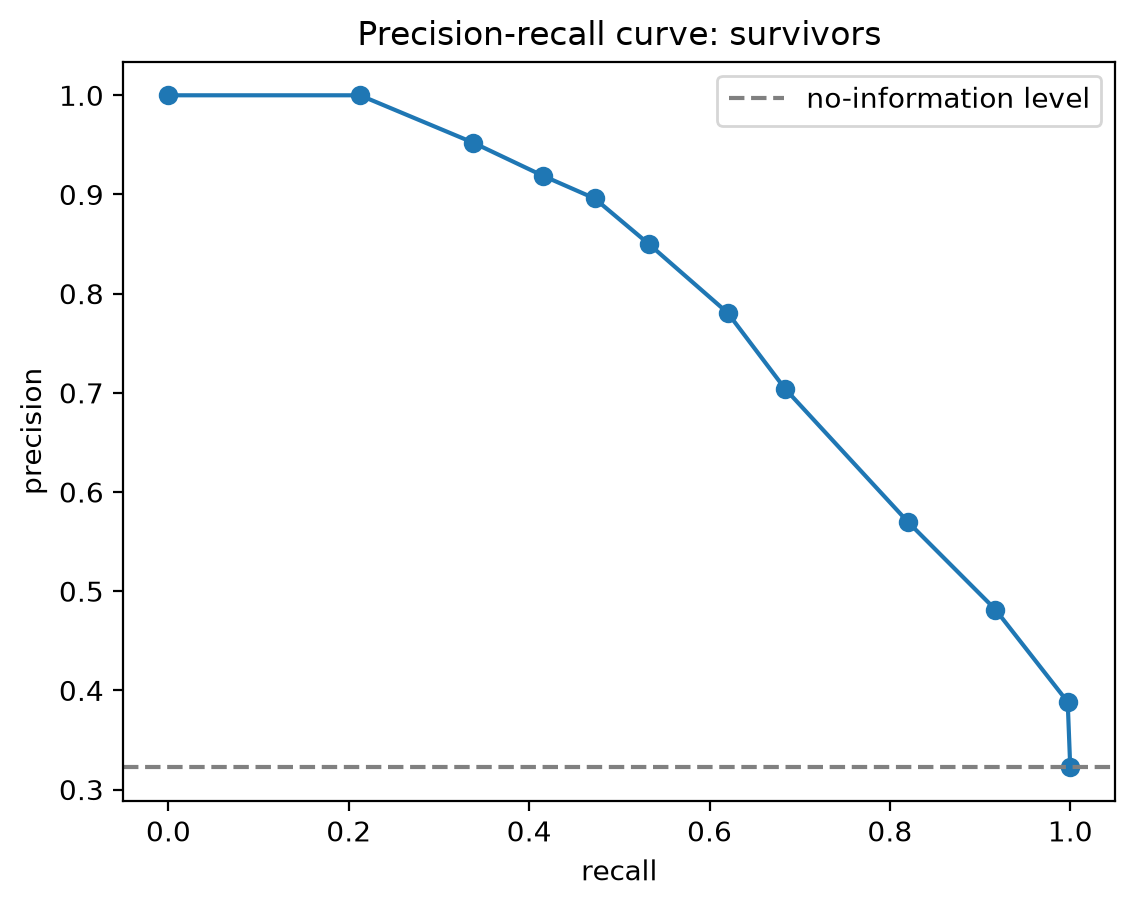

In [13]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

prec, rec, thr = precision_recall_curve(y_train, prob)

plt.plot(rec, prec, marker="o")
plt.axhline(y_train.mean(), color="grey", linestyle="--", label="no-information level")
plt.xlabel("recall")
plt.ylabel("precision")
plt.title("Precision-recall curve: survivors")
plt.legend()
plt.show()

The curve shows the trade-off between precision and recall for survivors. When the model only predicts survival for passengers it’s very confident about, it is almost always right but it misses most survivors. As it predicts survival for more passengers, it catches more survivors but more of its survival predictions are wrong. The curve stays well above the dashed line, so the model is much better than guessing.

7\. Plot the precision-recall curve for non-survivors. Interpret what you see.

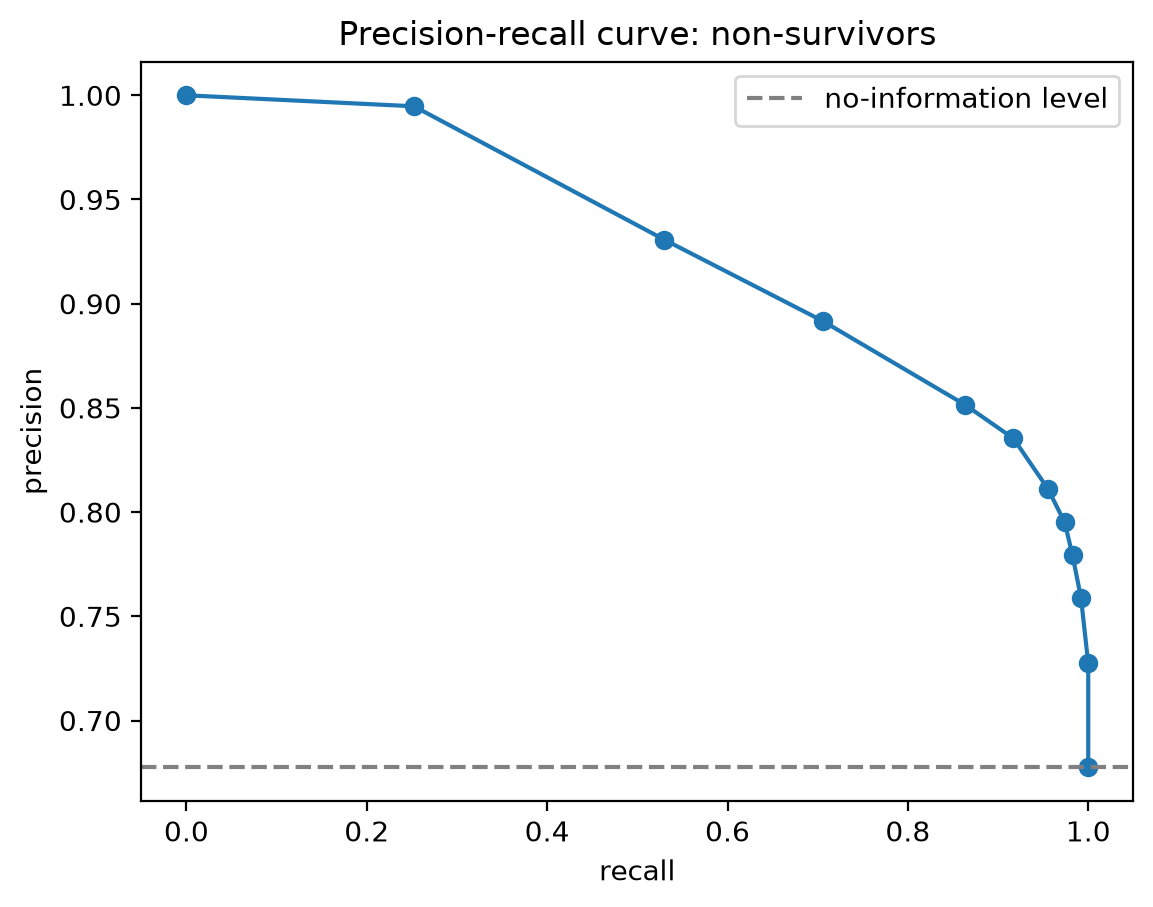

In [14]:
prob_0 = pipeline.predict_proba(X_train)[:, 0]   # P(did not survive)
prec0, rec0, thr0 = precision_recall_curve(y_train, prob_0, pos_label=0)

plt.plot(rec0, prec0, marker="o")
plt.axhline((y_train == 0).mean(), color="grey", linestyle="--", label="no-information level")
plt.xlabel("recall")
plt.ylabel("precision")
plt.title("Precision-recall curve: non-survivors")
plt.legend()
plt.show()

The curve shows the same trade-off as for survivors. As the model predicts “did not survive” for more passengers, it catches more non-survivors but precision drops. This curve stays high for longer compared to 6). The model catches over 90% of non-survivors while keeping precision above 80%, so it predicts non-survivors much better than survivors. The curve stays well above the dashed line (about 68%), so the model is much better than guessing.